# [0] EDA · Spotify Global Music Dataset (2009–2025) · v1

**Qué es:** análisis exploratorio clásico (distribuciones, categorías, nombres, géneros) del CSV de Kaggle
[wardabilal/spotify-global-music-dataset-20092025](https://www.kaggle.com/datasets/wardabilal/spotify-global-music-dataset-20092025).

**Qué cambia respecto a la versión anterior:** es la v1, no hay anterior.

**Decisión de fuente:** el dataset trae dos CSV. `track_data_final.csv` (8 778 canciones) contiene **todas** las
8 582 de `spotify_data clean.csv` más 196 adicionales, y conserva la información sin recortar (duración en ms, géneros
como lista). Se usa como fuente única; la sección [8] lo verifica y reporta las diferencias.

**Criterio de "hecho" (QA):** los datos que entran al proceso son los que salen. La sección [3] reconstruye cada columna
tipada hasta el texto original y exige igualdad fila a fila; cada tabla que alimenta un gráfico debe sumar el total de
origen (`assert_partition`). Si algo no cuadra, el notebook **falla**, no avisa.

**Dos audiencias:** las figuras `T*` son para equipo técnico (distribuciones, correlaciones, calidad); las `E*` son para
quien decide (mensaje en el título, una idea por gráfico). Todas se guardan en `artifacts/figures/`.

## [1] CONFIGURACIÓN

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "spotify_eda.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

import spotify_eda as se

pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(60)
cfg = se.Config()
se.apply_style(cfg)
C = cfg.colors
print("ROOT:", ROOT)

ROOT: C:\Users\KIN\Desktop\David\curso_prompt\repo\clase1\spotify-global-semantic-search


## [2] CARGA (texto puro → esquema explícito)

In [2]:
se.download_raw(cfg)                       # kagglehub -> copia en data/raw
path = cfg.raw_dir / cfg.main_file
raw = se.read_raw_strings(path)            # todo texto: nada se interpreta aún
df = se.build_typed(raw)                   # esquema explícito
genres_long = se.explode_genres(df)
artists = se.build_artists(df)
N = df.height
print(f"{N:,} canciones · {artists.height:,} artistas · {df['album_id'].n_unique():,} álbumes · {genres_long['genre'].n_unique()} géneros")
df.schema

C:\Users\KIN\Desktop\David\curso_prompt\repo\clase1\spotify-global-semantic-search\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


8,778 canciones · 2,548 artistas · 5,317 álbumes · 423 géneros


Schema([('track_id', String),
        ('track_name', String),
        ('track_number', Int32),
        ('track_popularity', Int32),
        ('track_duration_ms', Int64),
        ('explicit', Boolean),
        ('artist_name', String),
        ('artist_popularity', Int32),
        ('artist_followers', Int64),
        ('album_id', String),
        ('album_name', String),
        ('album_total_tracks', Int32),
        ('album_type', Enum(categories=['album', 'single', 'compilation'])),
        ('release_raw', String),
        ('release_precision', String),
        ('release_year', Int32),
        ('release_date', Date),
        ('genres', List(String)),
        ('genre_count', UInt32),
        ('duration_min', Float64)])

## [3] QA · entrada = salida

In [3]:
qa = se.run_qa(path, raw, df, genres_long)   # lanza AssertionError si falla algo
display(qa)
print(f"QA OK: {qa.height}/{qa.height} controles")

control,ok,detalle
str,bool,str
"""filas archivo == filas crudas""",true,"""8778 vs 8778"""
"""filas crudas == filas tipadas""",true,"""8778 vs 8778"""
"""track_id unico""",true,"""8778 unicos"""
"""track_id identico y en el mismo orden""",true,""""""
"""ida y vuelta: track_name""",true,"""0 filas distintas"""
"""ida y vuelta: artist_name""",true,"""0 filas distintas"""
"""ida y vuelta: album_name""",true,"""0 filas distintas"""
"""ida y vuelta: track_number""",true,"""0 filas distintas"""
"""ida y vuelta: track_popularity""",true,"""0 filas distintas"""


QA OK: 27/27 controles


## [4] CALIDAD DEL DATO · hallazgos por severidad

severidad,hallazgo,filas,pct
str,str,i64,f64
"""critico""","""artista vacio (sin popularidad/seguidores/generos)""",4,0.05
"""alto""","""sin ningun genero (lista vacia o artista vacio)""",4496,51.22
"""alto""","""lanzamiento fuera de 2009-2025""",1422,16.2
"""medio""","""fecha de lanzamiento '0000' (anio invalido)""",2,0.02
"""medio""","""fecha solo con anio o anio-mes (sin dia)""",201,2.29
"""medio""","""nombre de cancion o album vacio""",2,0.02
"""medio""","""track_number > album_total_tracks""",0,0.0
"""medio""","""duracion = 0 ms (placeholder; se excluye de T3)""",2,0.02
"""bajo""","""popularidad de cancion = 0""",521,5.94


Artistas con popularidad/seguidores distintos entre sus canciones: 802 de 2548


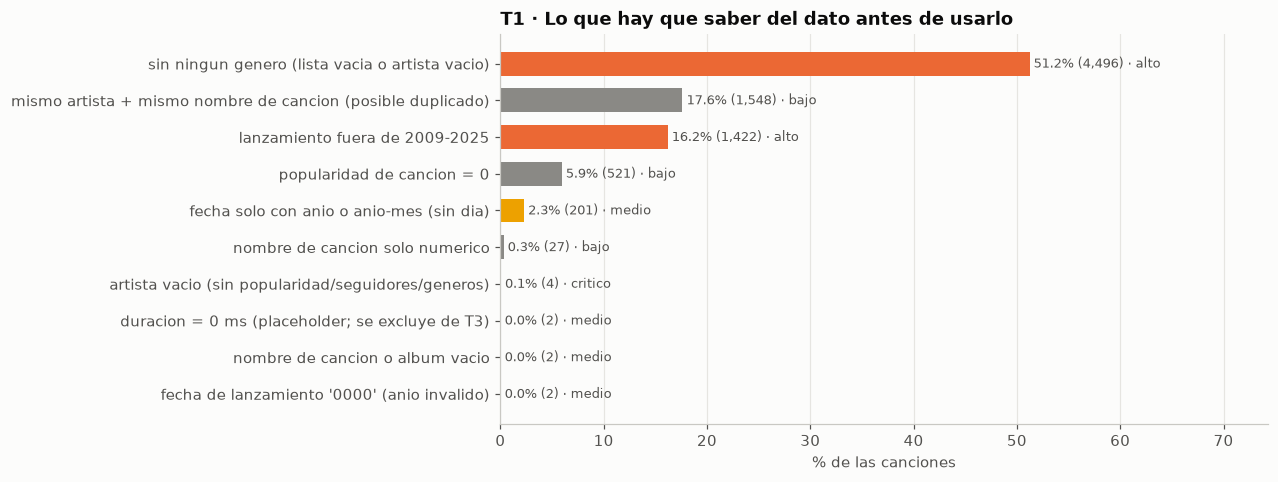

In [4]:
fnd = se.findings(df)
display(fnd)

# consistencia de los atributos de artista (se repiten por canción; deberían ser constantes)
incons = artists.filter((pl.col("pop_distinct") > 1) | (pl.col("followers_distinct") > 1))
print(f"Artistas con popularidad/seguidores distintos entre sus canciones: {incons.height} de {artists.height}")

sev = {"critico": "#e34948", "alto": "#eb6834", "medio": "#eda100", "bajo": "#8a8985"}
f = fnd.filter(pl.col("filas") > 0).sort("pct")
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(f["hallazgo"].str.slice(0, 62), f["pct"], color=[sev[s] for s in f["severidad"]], height=0.65)
for y, (p, n, s) in enumerate(zip(f["pct"], f["filas"], f["severidad"])):
    ax.text(p + 0.4, y, f"{p:.1f}% ({n:,}) · {s}", va="center", fontsize=8.5, color=C["ink2"])
ax.set_xlim(0, f["pct"].max() * 1.45)
ax.set_xlabel("% de las canciones")
ax.set_title("T1 · Lo que hay que saber del dato antes de usarlo")
ax.grid(axis="y", visible=False)
se.save_fig(fig, "T1_calidad_hallazgos", cfg); plt.show()

## [5] DISTRIBUCIONES NUMÉRICAS (técnico)

In [5]:
num = ["track_popularity", "artist_popularity", "artist_followers", "duration_min", "track_number", "album_total_tracks"]
desc = df.filter(pl.col("track_duration_ms") > 0).select(
    [pl.col(c).cast(pl.Float64).alias(c) for c in num]
).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
display(desc)
display(df.select(
    pl.col("explicit").mean().alias("pct_explicit"),
    (pl.col("album_type") == "album").mean().alias("pct_album"),
    (pl.col("album_type") == "single").mean().alias("pct_single"),
    (pl.col("album_type") == "compilation").mean().alias("pct_compilation"),
))

statistic,track_popularity,artist_popularity,artist_followers,duration_min,track_number,album_total_tracks
str,f64,f64,f64,f64,f64,f64
"""count""",8776.0,8772.0,8772.0,8776.0,8776.0,8776.0
"""null_count""",0.0,4.0,4.0,0.0,0.0,0.0
"""mean""",52.244758,69.97093,2.4360e7,3.503428,5.750456,13.782589
"""std""",24.065045,19.506421,3.8141e7,1.054242,6.018277,11.797828
"""min""",0.0,0.0,0.0,0.073133,1.0,1.0
"""5%""",0.0,31.0,3833.0,1.9999,1.0,1.0
"""25%""",39.0,60.0,514896.0,2.8991,1.0,6.0
"""50%""",58.0,74.0,6.29482e6,3.454667,4.0,13.0
"""75%""",71.0,84.0,3.0550549e7,3.995333,9.0,17.0


pct_explicit,pct_album,pct_single,pct_compilation
f64,f64,f64,f64
0.249715,0.686033,0.256095,0.057872


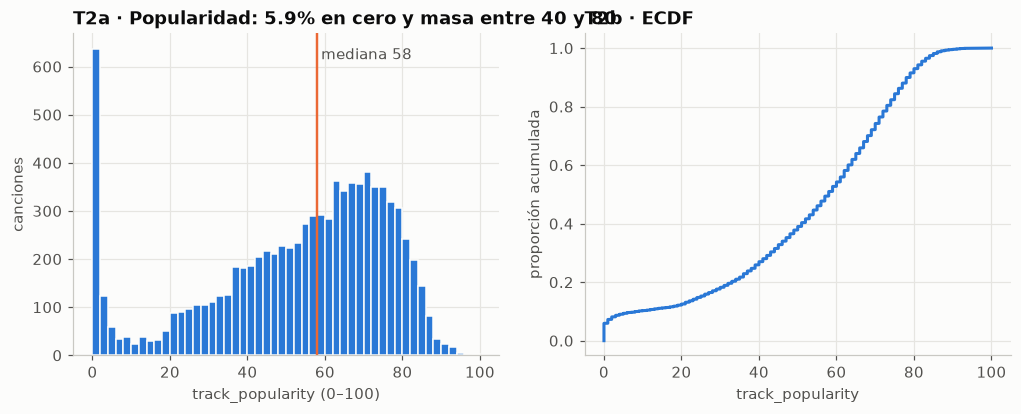

In [6]:
# T2 · popularidad de canción
pop = df["track_popularity"].to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(pop, bins=np.arange(0, 102, 2), color=C["blue"], edgecolor=C["surface"], linewidth=1)
axs[0].axvline(np.median(pop), color=C["orange"], lw=1.6)
axs[0].text(np.median(pop) + 1, axs[0].get_ylim()[1] * 0.92, f"mediana {np.median(pop):.0f}", color=C["ink2"])
axs[0].set(xlabel="track_popularity (0–100)", ylabel="canciones")
axs[0].set_title(f"T2a · Popularidad: {(pop == 0).mean():.1%} en cero y masa entre 40 y 80")
xs = np.sort(pop)
axs[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=C["blue"], lw=2)
axs[1].set(xlabel="track_popularity", ylabel="proporción acumulada")
axs[1].set_title("T2b · ECDF")
se.save_fig(fig, "T2_popularidad_cancion", cfg); plt.show()

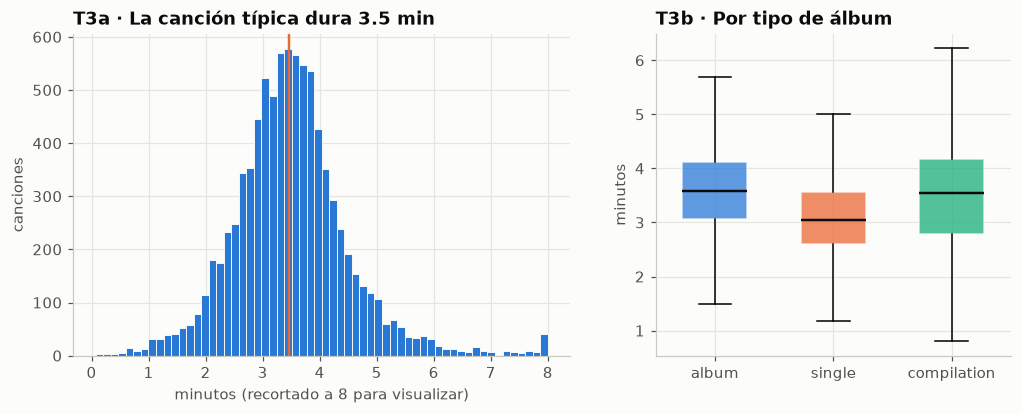

Canciones > 8 min: 37 | máxima: 13.5 min


In [7]:
# T3 · duración (se excluyen los 2 registros con 0 ms, ver hallazgos)
d = df.filter(pl.col("track_duration_ms") > 0)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
axs[0].hist(d["duration_min"].clip(upper_bound=8), bins=60, color=C["blue"], edgecolor=C["surface"], linewidth=0.6)
med = d["duration_min"].median()
axs[0].axvline(med, color=C["orange"], lw=1.6)
axs[0].set(xlabel="minutos (recortado a 8 para visualizar)", ylabel="canciones")
axs[0].set_title(f"T3a · La canción típica dura {med:.1f} min")
types = ["album", "single", "compilation"]
data = [d.filter(pl.col("album_type") == t)["duration_min"].clip(upper_bound=8).to_numpy() for t in types]
bp = axs[1].boxplot(data, tick_labels=types, patch_artist=True, widths=0.55, showfliers=False)
for patch, col in zip(bp["boxes"], [C["blue"], C["orange"], C["aqua"]]):
    patch.set(facecolor=col, alpha=0.75, edgecolor=C["surface"])
for m in bp["medians"]: m.set(color=C["ink"], lw=1.6)
axs[1].set(ylabel="minutos")
axs[1].set_title("T3b · Por tipo de álbum")
se.save_fig(fig, "T3_duracion", cfg); plt.show()
print("Canciones > 8 min:", int((d["duration_min"] > 8).sum()), "| máxima:", round(d["duration_min"].max(), 1), "min")

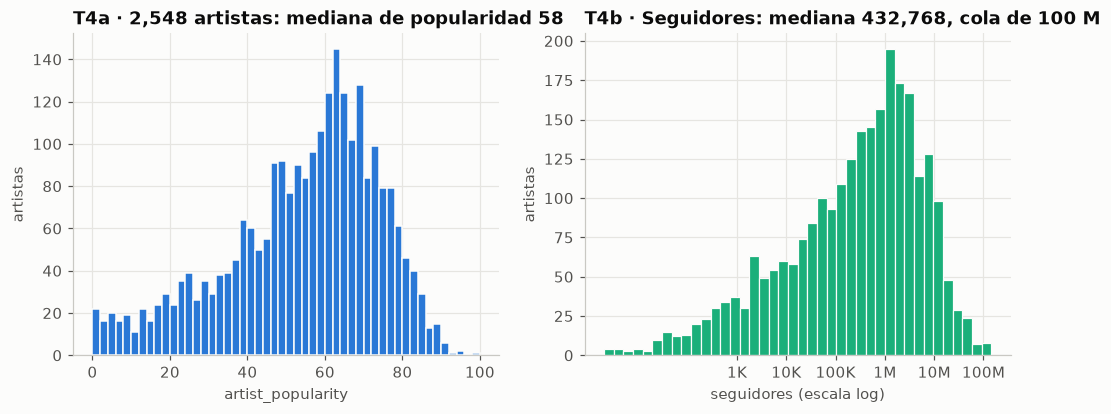

In [8]:
# T4 · artistas (una fila por artista, no por canción)
a = artists.drop_nulls(["artist_popularity", "artist_followers"])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(a["artist_popularity"], bins=np.arange(0, 102, 2), color=C["blue"], edgecolor=C["surface"], linewidth=1)
axs[0].set(xlabel="artist_popularity", ylabel="artistas")
axs[0].set_title(f"T4a · {a.height:,} artistas: mediana de popularidad {a['artist_popularity'].median():.0f}")
fol = a.filter(pl.col("artist_followers") > 0)["artist_followers"].to_numpy()
axs[1].hist(np.log10(fol), bins=40, color=C["aqua"], edgecolor=C["surface"], linewidth=0.8)
ticks = [3, 4, 5, 6, 7, 8]
axs[1].set_xticks(ticks, ["1K", "10K", "100K", "1M", "10M", "100M"])
axs[1].set(xlabel="seguidores (escala log)", ylabel="artistas")
axs[1].set_title(f"T4b · Seguidores: mediana {np.median(fol):,.0f}, cola de 100 M")
se.save_fig(fig, "T4_artistas", cfg); plt.show()

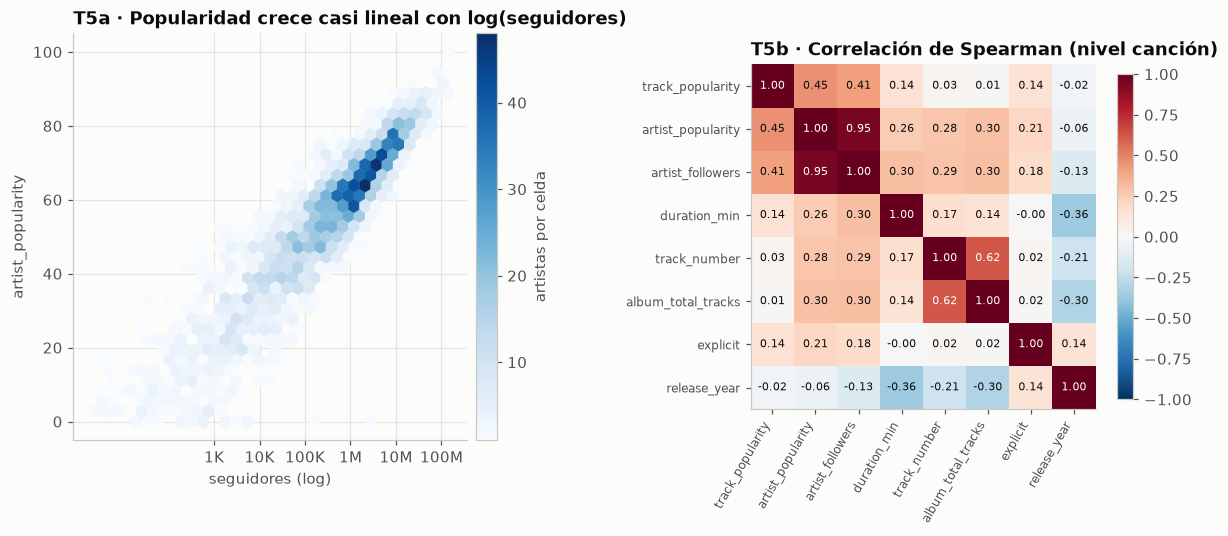

In [9]:
# T5 · relación popularidad de artista vs seguidores + correlaciones (Spearman, robusto a colas)
ax_df = a.filter(pl.col("artist_followers") > 0)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.45})
hb = axs[0].hexbin(np.log10(ax_df["artist_followers"]), ax_df["artist_popularity"], gridsize=32, cmap="Blues", mincnt=1, linewidths=0.2)
axs[0].set_xticks(ticks, ["1K", "10K", "100K", "1M", "10M", "100M"])
axs[0].set(xlabel="seguidores (log)", ylabel="artist_popularity")
axs[0].set_title("T5a · Popularidad crece casi lineal con log(seguidores)")
fig.colorbar(hb, ax=axs[0], label="artistas por celda", pad=0.02)

cols = ["track_popularity", "artist_popularity", "artist_followers", "duration_min", "track_number", "album_total_tracks", "explicit", "release_year"]
m = df.filter(pl.col("track_duration_ms") > 0).drop_nulls(cols).select([pl.col(c).cast(pl.Float64) for c in cols])
R = np.corrcoef(np.array([m[c].rank().to_numpy() for c in cols]))
im = axs[1].imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
axs[1].set_xticks(range(len(cols)), cols, rotation=60, ha="right", fontsize=8)
axs[1].set_yticks(range(len(cols)), cols, fontsize=8)
axs[1].grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        axs[1].text(j, i, f"{R[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(R[i, j]) > 0.55 else C["ink"])
axs[1].set_title("T5b · Correlación de Spearman (nivel canción)")
fig.colorbar(im, ax=axs[1], shrink=0.8)
se.save_fig(fig, "T5_relaciones", cfg); plt.show()

## [6] CATEGORÍAS, NOMBRES Y GÉNEROS (técnico)

album_type,canciones,mediana_pop,pct_explicit
enum,u32,f64,f64
"""album""",6022,61.0,0.261707
"""single""",2248,51.0,0.257562
"""compilation""",508,44.0,0.072835


explicit,canciones,mediana_pop
bool,u32,f64
false,6586,55.0
true,2192,64.0


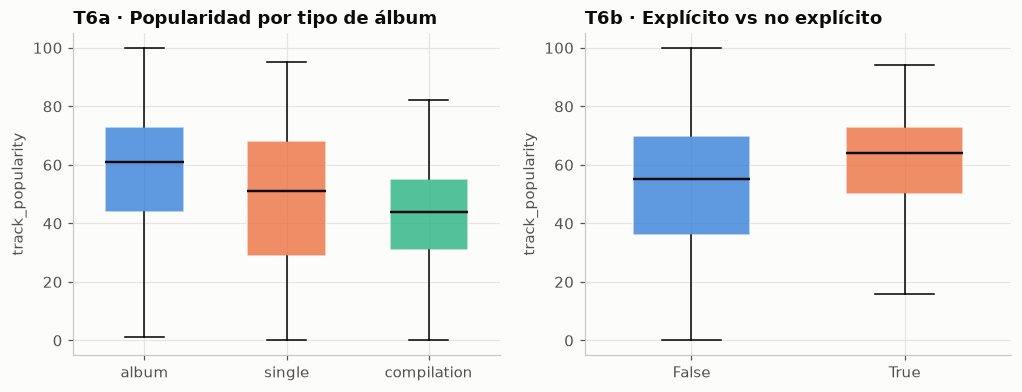

In [10]:
# T6 · tipo de álbum, explícito y popularidad por segmento (sin recorte de la muestra)
by_type = df.group_by("album_type").agg(
    pl.len().alias("canciones"), pl.col("track_popularity").median().alias("mediana_pop"),
    pl.col("explicit").mean().alias("pct_explicit"),
).sort("canciones", descending=True)
se.assert_partition(by_type, "canciones", N, "album_type")
by_exp = df.group_by("explicit").agg(pl.len().alias("canciones"), pl.col("track_popularity").median().alias("mediana_pop"))
se.assert_partition(by_exp, "canciones", N, "explicit")
display(by_type); display(by_exp)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, ttl in [(axs[0], "album_type", "T6a · Popularidad por tipo de álbum"), (axs[1], "explicit", "T6b · Explícito vs no explícito")]:
    cats = df[col].unique(maintain_order=True).sort().to_list()
    dd = [df.filter(pl.col(col) == c_)["track_popularity"].to_numpy() for c_ in cats]
    bp = ax.boxplot(dd, tick_labels=[str(c_) for c_ in cats], patch_artist=True, widths=0.55, showfliers=False)
    for patch, colr in zip(bp["boxes"], [C["blue"], C["orange"], C["aqua"]]): patch.set(facecolor=colr, alpha=0.75, edgecolor=C["surface"])
    for mm in bp["medians"]: mm.set(color=C["ink"], lw=1.6)
    ax.set(ylabel="track_popularity"); ax.set_title(ttl)
se.save_fig(fig, "T6_popularidad_segmentos", cfg); plt.show()

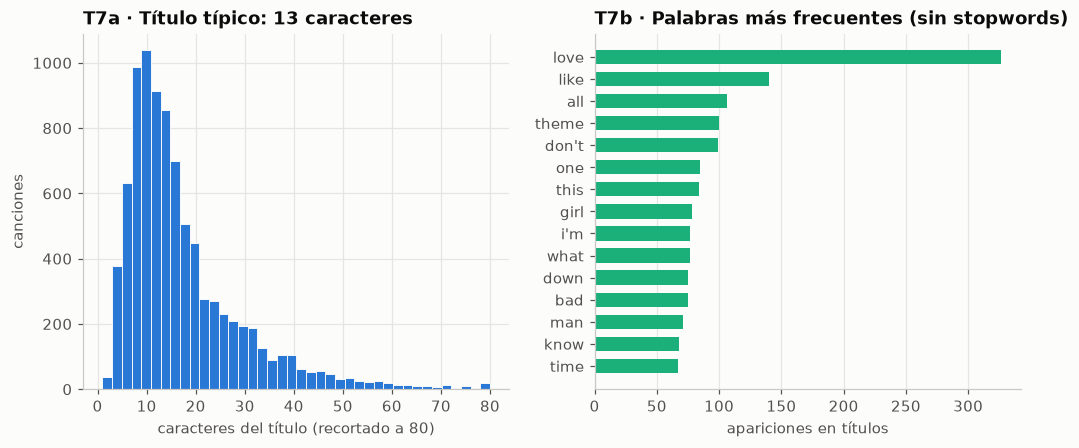

Títulos repetidos (distintas versiones/artistas):


track_name,n,artistas
str,u32,u32
"""Sorry""",8,5
"""Ghost""",8,7
"""Flowers""",8,6
"""Home""",8,7
"""Breathe""",7,6
"""Paradise""",6,6
"""Falling""",6,4
"""Strangers""",6,6
"""Memories""",6,5


In [11]:
# T7 · nombres: longitud del título y palabras más frecuentes
nm = df.drop_nulls("track_name").with_columns(pl.col("track_name").str.len_chars().alias("len"))
stop = set("the a an of to in on and feat with ft from for is my you me i it your at by remix version remastered radio edit mix live".split())
words = (nm.select(pl.col("track_name").str.to_lowercase().str.replace_all(r"[^\w\s']", " ").str.split(" ").alias("w"))
           .explode("w").filter((pl.col("w").str.len_chars() > 2) & ~pl.col("w").is_in(list(stop)))
           .group_by("w").len().sort("len", descending=True).head(cfg.top_n))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].hist(nm["len"].clip(upper_bound=80), bins=40, color=C["blue"], edgecolor=C["surface"], linewidth=0.6)
axs[0].set(xlabel="caracteres del título (recortado a 80)", ylabel="canciones")
axs[0].set_title(f"T7a · Título típico: {nm['len'].median():.0f} caracteres")
w = words.sort("len")
axs[1].barh(w["w"], w["len"], color=C["aqua"], height=0.65)
axs[1].set_xlabel("apariciones en títulos"); axs[1].grid(axis="y", visible=False)
axs[1].set_title("T7b · Palabras más frecuentes (sin stopwords)")
se.save_fig(fig, "T7_nombres", cfg); plt.show()

rep = (df.drop_nulls("track_name").group_by("track_name").agg(pl.len().alias("n"), pl.col("artist_name").n_unique().alias("artistas"))
         .sort("n", descending=True).head(10))
print("Títulos repetidos (distintas versiones/artistas):"); display(rep)

423 géneros distintos; 107 aparecen en una sola canción; 60 tienen >= 30 canciones


grupo,canciones
str,i64
"""con género""",4282
"""sin género""",4496


genre,canciones,artistas,mediana_pop
str,u32,u32,f64
"""soundtrack""",451,88,42.0
"""pop""",386,8,65.0
"""rap""",304,19,67.0
"""country""",276,99,57.0
"""rock""",270,39,58.0
"""soft pop""",224,12,63.0
"""art pop""",181,18,55.0
"""hip hop""",149,23,63.0
"""nu metal""",123,14,57.0


Géneros por canción (0 = sin género):


genre_count,count
u32,u32
0,4496
1,2374
2,1124
3,317
4,299
5,138
6,19
7,7
8,3


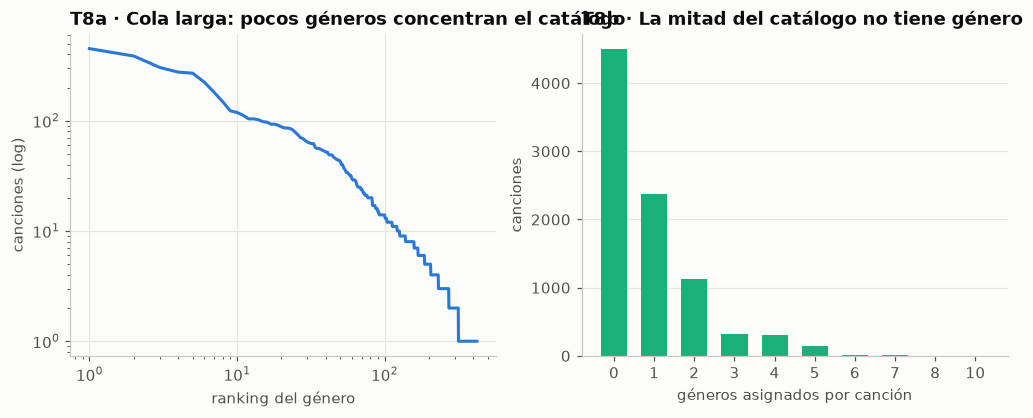

In [12]:
# T8 · géneros: cardinalidad, cobertura y cola larga
g_all = genres_long.group_by("genre").agg(
    pl.len().alias("canciones"), pl.col("artist_name").n_unique().alias("artistas"),
    pl.col("track_popularity").median().alias("mediana_pop"),
).sort("canciones", descending=True)
cover = pl.DataFrame({"grupo": ["con género", "sin género"],
                      "canciones": [genres_long["track_id"].n_unique(), N - genres_long["track_id"].n_unique()]})
se.assert_partition(cover, "canciones", N, "cobertura de género")
print(f"{g_all.height} géneros distintos; {int((g_all['canciones'] == 1).sum())} aparecen en una sola canción; "
      f"{int((g_all['canciones'] >= cfg.min_genre_tracks).sum())} tienen >= {cfg.min_genre_tracks} canciones")
display(cover); display(g_all.head(cfg.top_n))
print("Géneros por canción (0 = sin género):"); display(df["genre_count"].fill_null(0).value_counts().sort("genre_count"))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
rank = g_all["canciones"].to_numpy()
axs[0].loglog(np.arange(1, len(rank) + 1), rank, color=C["blue"], lw=2)
axs[0].set(xlabel="ranking del género", ylabel="canciones (log)")
axs[0].set_title("T8a · Cola larga: pocos géneros concentran el catálogo")
c2 = df["genre_count"].fill_null(0).value_counts().sort("genre_count")
axs[1].bar(c2["genre_count"].cast(pl.String), c2["count"], color=C["aqua"], width=0.65)
axs[1].set(xlabel="géneros asignados por canción", ylabel="canciones")
axs[1].set_title("T8b · La mitad del catálogo no tiene género")
axs[1].grid(axis="x", visible=False)
se.save_fig(fig, "T8_generos_tecnico", cfg); plt.show()

## [7] PARA TOMADORES DE DECISIONES

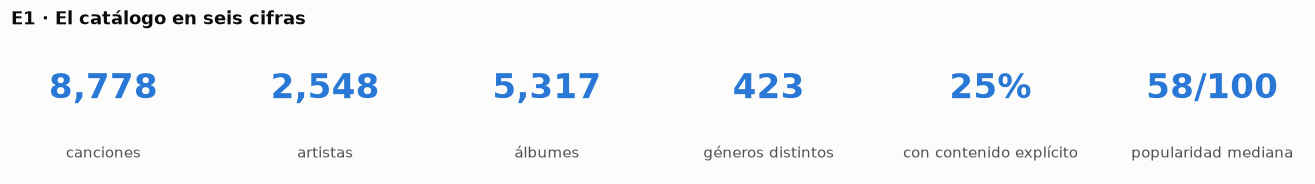

In [13]:
# E1 · tarjeta de cifras clave
kpis = [
    (f"{N:,}", "canciones"), (f"{artists.height:,}", "artistas"), (f"{df['album_id'].n_unique():,}", "álbumes"),
    (f"{genres_long['genre'].n_unique()}", "géneros distintos"), (f"{df['explicit'].mean():.0%}", "con contenido explícito"),
    (f"{df['track_popularity'].median():.0f}/100", "popularidad mediana"),
]
fig, axs = plt.subplots(1, len(kpis), figsize=(12, 1.7))
for ax, (v, lab) in zip(axs, kpis):
    ax.axis("off"); ax.text(0.5, 0.58, v, ha="center", fontsize=22, fontweight="bold", color=C["blue"])
    ax.text(0.5, 0.12, lab, ha="center", fontsize=9.5, color=C["ink2"])
fig.subplots_adjust(left=0.01, right=0.99, top=0.8)
fig.suptitle("E1 · El catálogo en seis cifras", x=0.01, ha="left", fontweight="bold", fontsize=12)
se.save_fig(fig, "E1_cifras_clave", cfg); plt.show()

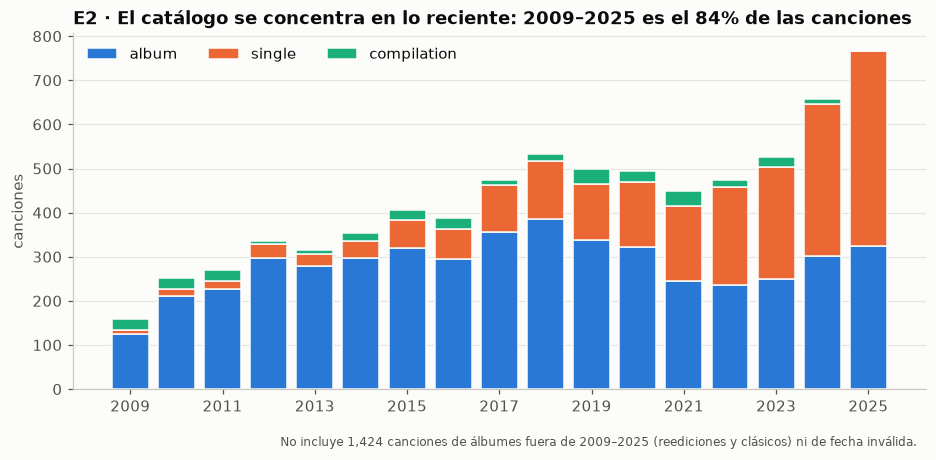

In [14]:
# E2 · catálogo por año de lanzamiento del álbum, por tipo
lo, hi = cfg.release_window
yr = (df.filter(pl.col("release_year").is_between(lo, hi)).group_by("release_year", "album_type").len()
        .pivot(on="album_type", index="release_year", values="len").fill_null(0).sort("release_year"))
outside = int(df.filter(~pl.col("release_year").is_between(lo, hi) | pl.col("release_year").is_null()).height)
tot_win = int(sum(yr[t].sum() for t in ["album", "single", "compilation"]))
assert tot_win + outside == N, "[QA grafico] E2: ventana + fuera de ventana != total"
fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = np.zeros(yr.height)
for t, colr in zip(["album", "single", "compilation"], [C["blue"], C["orange"], C["aqua"]]):
    ax.bar(yr["release_year"], yr[t], bottom=bottom, color=colr, label=t, width=0.8, edgecolor=C["surface"], linewidth=1)
    bottom += yr[t].to_numpy()
last, prev = int(bottom[-1]), int(bottom[-2])
ax.set(ylabel="canciones")
ax.set_xticks(range(lo, hi + 1, 2))
ax.set_title(f"E2 · El catálogo se concentra en lo reciente: {lo}–{hi} es el {tot_win / N:.0%} de las canciones")
ax.legend(frameon=False, ncol=3, loc="upper left"); ax.grid(axis="x", visible=False)
ax.text(0.99, -0.16, f"No incluye {outside:,} canciones de álbumes fuera de {lo}–{hi} (reediciones y clásicos) ni de fecha inválida.",
        transform=ax.transAxes, ha="right", fontsize=8, color=C["ink2"])
se.save_fig(fig, "E2_catalogo_por_anio", cfg); plt.show()

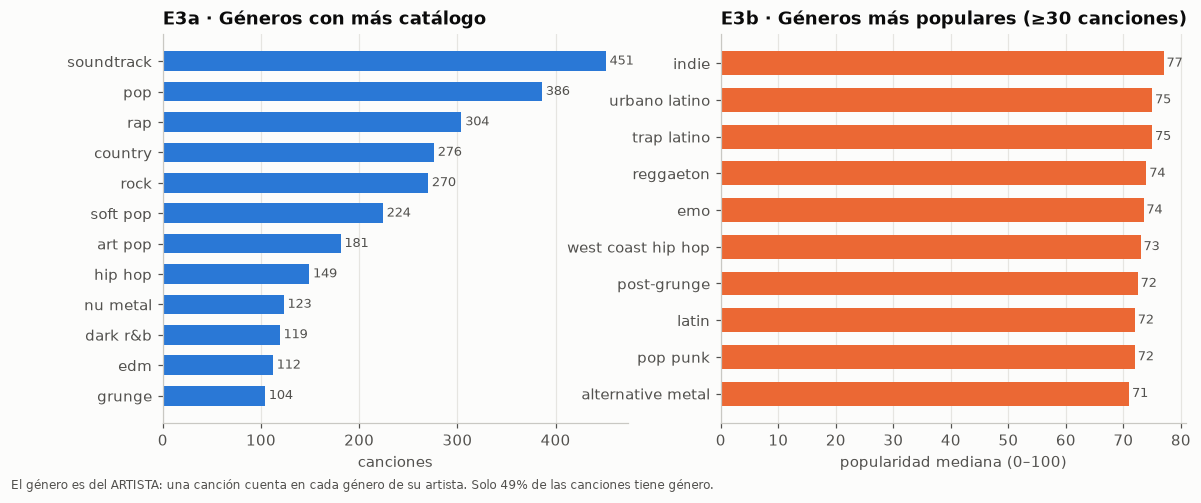

In [15]:
# E3 · géneros: dónde está el volumen y dónde la popularidad
top_g = g_all.head(12).sort("canciones")
pop_g = g_all.filter(pl.col("canciones") >= cfg.min_genre_tracks).sort("mediana_pop", descending=True).head(10).sort("mediana_pop")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
axs[0].barh(top_g["genre"], top_g["canciones"], color=C["blue"], height=0.65)
for y, v in enumerate(top_g["canciones"]): axs[0].text(v + 4, y, f"{v:,}", va="center", fontsize=8.5, color=C["ink2"])
axs[0].set_xlabel("canciones"); axs[0].grid(axis="y", visible=False)
axs[0].set_title("E3a · Géneros con más catálogo")
axs[1].barh(pop_g["genre"], pop_g["mediana_pop"], color=C["orange"], height=0.65)
for y, v in enumerate(pop_g["mediana_pop"]): axs[1].text(v + 0.5, y, f"{v:.0f}", va="center", fontsize=8.5, color=C["ink2"])
axs[1].set_xlabel("popularidad mediana (0–100)"); axs[1].grid(axis="y", visible=False)
axs[1].set_title(f"E3b · Géneros más populares (≥{cfg.min_genre_tracks} canciones)")
fig.text(0.01, -0.02, "El género es del ARTISTA: una canción cuenta en cada género de su artista. "
         f"Solo {cover['canciones'][0] / N:.0%} de las canciones tiene género.", fontsize=8, color=C["ink2"])
se.save_fig(fig, "E3_generos_decision", cfg); plt.show()

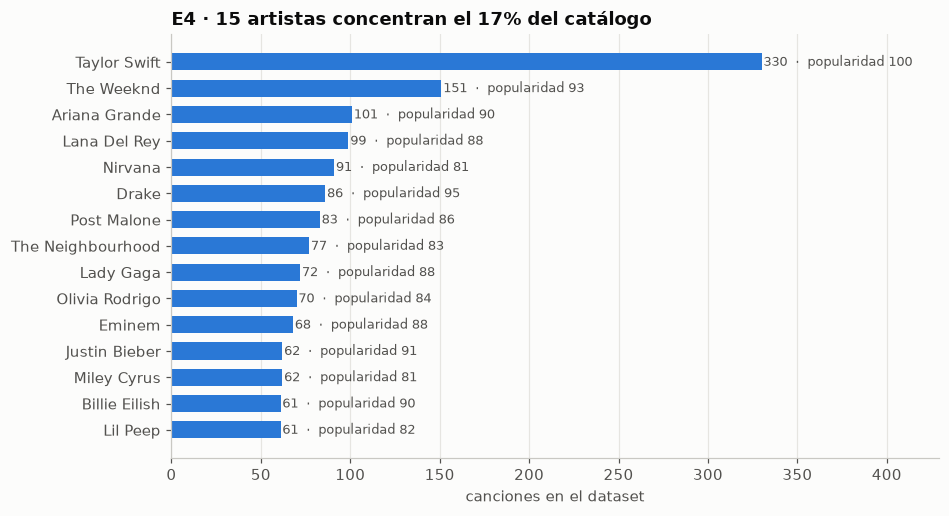

In [16]:
# E4 · artistas con más presencia y su popularidad
top_a = artists.sort("n_tracks", descending=True).head(cfg.top_n).sort("n_tracks")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_a["artist_name"], top_a["n_tracks"], color=C["blue"], height=0.65)
for y, (n, p) in enumerate(zip(top_a["n_tracks"], top_a["artist_popularity"])):
    ax.text(n + 1, y, f"{n}  ·  popularidad {p:.0f}" if p is not None else f"{n}", va="center", fontsize=8.5, color=C["ink2"])
ax.set_xlim(0, top_a["n_tracks"].max() * 1.3); ax.grid(axis="y", visible=False)
ax.set_xlabel("canciones en el dataset")
share = top_a["n_tracks"].sum() / N
ax.set_title(f"E4 · {cfg.top_n} artistas concentran el {share:.0%} del catálogo")
se.save_fig(fig, "E4_artistas_top", cfg); plt.show()

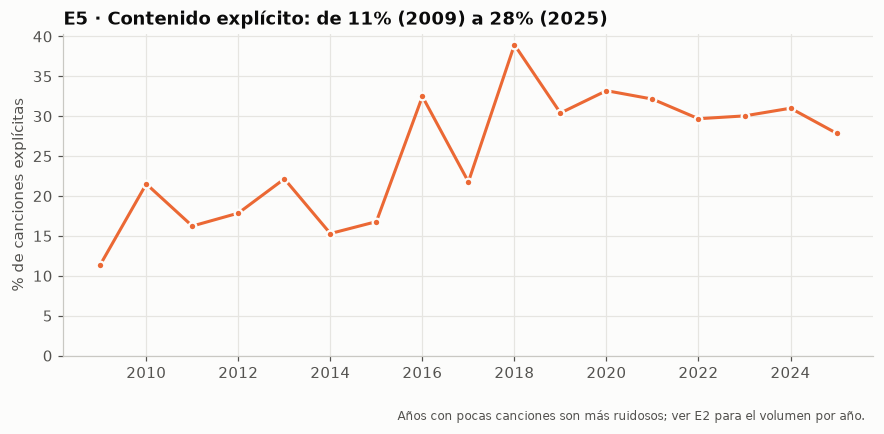

In [17]:
# E5 · evolución del contenido explícito
ex = (df.filter(pl.col("release_year").is_between(lo, hi)).group_by("release_year")
        .agg(pl.col("explicit").mean().alias("pct"), pl.len().alias("n")).sort("release_year"))
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(ex["release_year"], ex["pct"] * 100, color=C["orange"], lw=2, marker="o", ms=5, markeredgecolor=C["surface"], markeredgewidth=1.5)
ax.set(ylabel="% de canciones explícitas", ylim=(0, None))
a0, a1 = ex["pct"][0] * 100, ex["pct"][-1] * 100
ax.set_title(f"E5 · Contenido explícito: de {a0:.0f}% ({lo}) a {a1:.0f}% ({hi})")
ax.text(0.99, -0.2, "Años con pocas canciones son más ruidosos; ver E2 para el volumen por año.", transform=ax.transAxes, ha="right", fontsize=8, color=C["ink2"])
se.save_fig(fig, "E5_explicito_tiempo", cfg); plt.show()

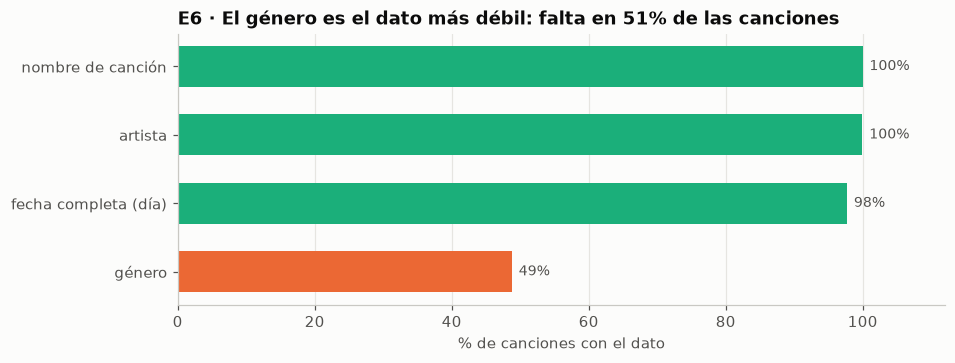

In [18]:
# E6 · cobertura de metadatos: riesgo para búsqueda por género/semántica
cov = pl.DataFrame({
    "campo": ["artista", "género", "fecha completa (día)", "nombre de canción"],
    "completo": [N - int(df["artist_name"].is_null().sum()), cover["canciones"][0],
                 int((df["release_precision"] == "day").sum()), N - int(df["track_name"].is_null().sum())],
}).with_columns((pl.col("completo") / N).alias("pct")).sort("pct")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(cov["campo"], cov["pct"] * 100, color=[C["orange"] if p < 0.8 else C["aqua"] for p in cov["pct"]], height=0.6)
for y, p in enumerate(cov["pct"]): ax.text(p * 100 + 1, y, f"{p:.0%}", va="center", fontsize=9, color=C["ink2"])
ax.set(xlim=(0, 112), xlabel="% de canciones con el dato"); ax.grid(axis="y", visible=False)
ax.set_title(f"E6 · El género es el dato más débil: falta en {1 - cov['pct'][0]:.0%} de las canciones")
se.save_fig(fig, "E6_cobertura_metadatos", cfg); plt.show()

## [8] VERIFICACIÓN CONTRA EL OTRO CSV

In [19]:
sec = se.read_raw_strings(cfg.raw_dir / cfg.secondary_file)
ids_main, ids_sec = set(raw["track_id"]), set(sec["track_id"])
print(f"main={len(ids_main):,} · secundario={len(ids_sec):,} · en ambos={len(ids_main & ids_sec):,} · "
      f"solo main={len(ids_main - ids_sec):,} · solo secundario={len(ids_sec - ids_main):,}")
assert ids_sec <= ids_main, "El CSV secundario trae canciones que no están en el principal"
j = raw.join(sec, on="track_id", suffix="_sec")
diffs = {c: int((j[c] != j[c + "_sec"]).sum()) for c in ["track_name", "track_popularity", "artist_popularity", "artist_followers", "album_release_date"]}
print("Filas con valor distinto en las 8 582 comunes:", diffs)

main=8,778 · secundario=8,582 · en ambos=8,582 · solo main=196 · solo secundario=0
Filas con valor distinto en las 8 582 comunes: {'track_name': 123, 'track_popularity': 0, 'artist_popularity': 8582, 'artist_followers': 8582, 'album_release_date': 198}


## [9] EXPORTACIÓN Y QA DE SALIDA

In [20]:
cfg.processed_dir.mkdir(parents=True, exist_ok=True)
cfg.tables_dir.mkdir(parents=True, exist_ok=True)
df.write_parquet(cfg.processed_dir / "tracks.parquet")
genres_long.write_parquet(cfg.processed_dir / "track_genres.parquet")
artists.write_parquet(cfg.processed_dir / "artists.parquet")
for name, t in {"qa_controles": qa, "hallazgos": fnd, "generos": g_all, "tipo_album": by_type, "artistas_top": artists.sort("n_tracks", descending=True).head(50)}.items():
    t.write_csv(cfg.tables_dir / f"{name}.csv")

# lo exportado debe ser idéntico a lo que salió del proceso
assert pl.read_parquet(cfg.processed_dir / "tracks.parquet").equals(df), "tracks.parquet != df"
assert pl.read_parquet(cfg.processed_dir / "track_genres.parquet").equals(genres_long), "track_genres.parquet != genres_long"
assert pl.read_parquet(cfg.processed_dir / "artists.parquet").equals(artists), "artists.parquet != artists"
figs = sorted(p.name for p in cfg.figures_dir.glob("*.png"))
assert len(figs) == 14, f"se esperaban 14 figuras, hay {len(figs)}"
print("QA de salida OK ·", len(figs), "figuras ·", N, "filas en tracks.parquet")

QA de salida OK · 14 figuras · 8778 filas en tracks.parquet


## [10] CÓMO LEER LOS RESULTADOS

In [21]:
top3 = ", ".join(g_all.head(3)["genre"])
display(Markdown(f'''
**Alcance.** {N:,} canciones de {artists.height:,} artistas. Pese al nombre (2009–2025), {fnd.filter(pl.col("hallazgo").str.starts_with("lanzamiento fuera"))["filas"][0]:,} canciones
({fnd.filter(pl.col("hallazgo").str.starts_with("lanzamiento fuera"))["pct"][0]:.0f}%) pertenecen a álbumes fuera de esa ventana: es la fecha del **álbum**, no de la canción, y hay reediciones.

**Qué dice el dato.** La popularidad es asimétrica con {(df["track_popularity"] == 0).mean():.1%} de canciones en cero; la duración típica es {med:.1f} min;
los seguidores abarcan cinco órdenes de magnitud (por eso se grafican en escala log). Géneros con más catálogo: {top3}.

**Límites que condicionan cualquier conclusión.**
1. El género es del artista y falta en {1 - cover["canciones"][0] / N:.0%} de las canciones: no sirve solo como etiqueta de canción.
2. El CSV no trae `artist_id`: la identidad de artista es el nombre; homónimos **POR VERIFICAR**.
3. La popularidad de Spotify es una foto del momento de la descarga; no está verificado cuándo se tomó **(POR VERIFICAR)**.
4. Las correlaciones son descriptivas, no causales.
5. Es una muestra de la plataforma, no su catálogo completo: un solo artista (Taylor Swift) aporta 330 canciones, así que los rankings reflejan cómo se armó el dataset, no el mercado. Cómo se muestreó **POR VERIFICAR**.

**QA.** {qa.height}/{qa.height} controles de entrada y la reconstrucción de la salida (parquet) coinciden con lo cargado.
Figuras `T*` (técnicas) y `E*` (decisión) en `artifacts/figures/`; tablas en `artifacts/tables/`; datos tipados en `data/processed/`.
'''))


**Alcance.** 8,778 canciones de 2,548 artistas. Pese al nombre (2009–2025), 1,422 canciones
(16%) pertenecen a álbumes fuera de esa ventana: es la fecha del **álbum**, no de la canción, y hay reediciones.

**Qué dice el dato.** La popularidad es asimétrica con 5.9% de canciones en cero; la duración típica es 3.5 min;
los seguidores abarcan cinco órdenes de magnitud (por eso se grafican en escala log). Géneros con más catálogo: soundtrack, pop, rap.

**Límites que condicionan cualquier conclusión.**
1. El género es del artista y falta en 51% de las canciones: no sirve solo como etiqueta de canción.
2. El CSV no trae `artist_id`: la identidad de artista es el nombre; homónimos **POR VERIFICAR**.
3. La popularidad de Spotify es una foto del momento de la descarga; no está verificado cuándo se tomó **(POR VERIFICAR)**.
4. Las correlaciones son descriptivas, no causales.
5. Es una muestra de la plataforma, no su catálogo completo: un solo artista (Taylor Swift) aporta 330 canciones, así que los rankings reflejan cómo se armó el dataset, no el mercado. Cómo se muestreó **POR VERIFICAR**.

**QA.** 27/27 controles de entrada y la reconstrucción de la salida (parquet) coinciden con lo cargado.
Figuras `T*` (técnicas) y `E*` (decisión) en `artifacts/figures/`; tablas en `artifacts/tables/`; datos tipados en `data/processed/`.
